[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU-USUARIO/TechDF-CRISP-DM-Analysis/blob/main/notebooks/pratica_crispdm_techdf.ipynb)

# TechDF – Análise de Dados com CRISP-DM
**Gustavo Carvalho de Oliveira** · UDF – Centro Universitário · Ciência de Dados e Aprendizagem de Máquina (A1) · Profa. Kadidja Valéria

Projeto: aplicar as seis fases do CRISP-DM à **TechDF**, loja on-line fictícia de informática que vende para o Distrito Federal.

* **P1.** Quais segmentos de clientes existem e que ação de relacionamento oferecer a cada um? (K-means)
* **P2.** É possível prever quais clientes não vão comprar nos próximos 90 dias? (classificação)

> **Dados simulados.** A base é gerada neste notebook com regras de negócio e erros inseridos de propósito. Os números demonstram o método e não descrevem uma empresa real.

In [1]:
import hashlib, json, os, warnings
pd_opts = None
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, recall_score, precision_score, f1_score,
                             roc_auc_score)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
warnings.filterwarnings('ignore')
SEMENTE = 42
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
rng = np.random.default_rng(SEMENTE)
BASE = '../dados'; PROC = f'{BASE}/processed'; DASH = '../Dashboard'
for p in [BASE, PROC, DASH]: os.makedirs(p, exist_ok=True)
sns.set_theme(style='whitegrid')
FIM = pd.Timestamp('2026-06-30')   # data da extração

## Fase 1 – Entendimento do negócio
| Pergunta | Meta técnica | Critério técnico | Critério de negócio |
|---|---|---|---|
| P1 – Segmentos | K-means sobre recência, frequência, valor, ticket e mix de produtos | Silhueta > 0,25 e menor grupo ≥ 5% | Ação por segmento com taxa de recompra 15% maior que o grupo controle |
| P2 – Risco de abandono | Classificar "não compra nos próximos 90 dias" | Recall ≥ 0,70 e F1 acima da regressão logística | Recuperar 10% dos clientes alertados em 90 dias |

Hipóteses: **H1** atraso na entrega aumenta o abandono; **H2** as regiões mais distantes do centro de distribuição recebem com mais atraso; **H3** clientes do programa de fidelidade compram com mais frequência.

## Fase 2 – Entendimento dos dados
### 2.1 Geração da base simulada (mesma estrutura de um banco relacional de e-commerce)

In [2]:
regioes = pd.DataFrame({'idRegiao': range(1, 9), 'regiao': ['Plano Piloto', 'Guará', 'Águas Claras', 'Taguatinga',
                        'Sobradinho', 'Samambaia', 'Ceilândia', 'Gama']})
prazo_regiao = dict(zip(range(1, 9), [1.0, 1.0, 1.5, 2.0, 3.0, 3.5, 4.0, 5.0]))
categorias = pd.DataFrame({'idCategoria': range(1, 9), 'categoria': ['Notebooks', 'Celulares', 'Periféricos',
                           'Monitores', 'Armazenamento', 'Acessórios', 'Games', 'Rede']})
catalogo = {1: [('Notebook i5 15"', 3499.9), ('Notebook i7 14"', 5299.0), ('Notebook Ryzen 5', 3899.0), ('Chromebook 11"', 1599.0), ('Notebook gamer RTX', 7499.0)],
            2: [('Smartphone 128 GB', 1899.0), ('Smartphone 256 GB', 2999.0), ('Smartphone básico', 899.0), ('Smartphone premium', 5999.0)],
            3: [('Mouse sem fio', 79.9), ('Teclado mecânico', 289.0), ('Headset USB', 199.0), ('Webcam Full HD', 249.0), ('Mouse gamer', 179.0)],
            4: [('Monitor 24" Full HD', 899.0), ('Monitor 27" QHD', 1699.0), ('Monitor 34" ultrawide', 2899.0)],
            5: [('SSD 1 TB', 429.9), ('SSD 500 GB', 259.9), ('HD externo 2 TB', 449.0), ('Pen drive 64 GB', 39.9), ('Cartão microSD 128 GB', 69.9)],
            6: [('Cabo USB-C', 29.9), ('Carregador 65 W', 159.0), ('Capa para notebook', 89.9), ('Suporte para monitor', 149.0), ('Hub USB', 119.0)],
            7: [('Console de videogame', 3999.0), ('Controle sem fio', 399.0), ('Jogo lançamento', 299.0), ('Cadeira gamer', 1199.0)],
            8: [('Roteador Wi-Fi 6', 499.0), ('Repetidor Wi-Fi', 149.0), ('Switch 8 portas', 189.0)]}
produtos = pd.DataFrame([(c, n, p) for c, itens in catalogo.items() for n, p in itens],
                        columns=['idCategoria', 'produto', 'precoLista'])
produtos.insert(0, 'idProduto', range(1, len(produtos) + 1))
formas = pd.DataFrame({'idFormaPagamento': [1, 2, 3, 4], 'formaPagamento': ['Cartão de crédito', 'Pix', 'Boleto', 'Cartão de débito']})

# Perfis latentes (não ficam na base): taxa de pedidos/mês, chance base de abandonar, pagamento e mix de categorias
perfis = {'fiel':     dict(p=0.20, taxa=1.10, sair=0.03, pag=[.45, .35, .05, .15], cat=[.10, .10, .20, .10, .15, .20, .05, .10]),
          'ocasional': dict(p=0.45, taxa=0.25, sair=0.14, pag=[.50, .30, .10, .10], cat=[.15, .20, .15, .10, .10, .15, .05, .10]),
          'gamer':    dict(p=0.15, taxa=0.45, sair=0.07, pag=[.65, .20, .05, .10], cat=[.15, .05, .15, .15, .05, .05, .40, .00]),
          'promocao': dict(p=0.20, taxa=0.55, sair=0.10, pag=[.15, .40, .40, .05], cat=[.02, .05, .30, .03, .20, .35, .02, .03])}
N = 1200
nomes_perfil = list(perfis)
perfil_cli = rng.choice(nomes_perfil, N, p=[perfis[k]['p'] for k in nomes_perfil])
peso_reg = np.array([.18, .08, .12, .16, .08, .12, .18, .08])
clientes = pd.DataFrame({'idCliente': range(1, N + 1),
                         'emailCliente': [f'cliente{i:04d}@exemplo.com' for i in range(1, N + 1)],
                         'idRegiao': rng.choice(range(1, 9), N, p=peso_reg),
                         'dataCadastro': pd.to_datetime('2025-01-01') + pd.to_timedelta(rng.integers(0, 455, N), unit='D')})
clientes['programaFidelidade'] = np.where(perfil_cli == 'fiel', rng.random(N) < 0.55, rng.random(N) < 0.15)

ped, itens = [], []
for i, cli in clientes.iterrows():
    pf = perfis[perfil_cli[i]]
    t = cli['dataCadastro'] + pd.Timedelta(days=float(rng.exponential(10)))
    while t <= FIM:
        status = rng.choice(['Entregue', 'Cancelado', 'Devolvido'], p=[.92, .06, .02])
        forma = rng.choice([1, 2, 3, 4], p=pf['pag'])
        prazo = aval = None
        if status != 'Cancelado':
            prazo = prazo_regiao[cli['idRegiao']] + (2 if forma == 3 else 0) + rng.gamma(2, 0.8)
            if rng.random() < 0.04: prazo += rng.integers(6, 12)          # problema com a transportadora
            prazo = int(round(prazo))
            if rng.random() > 0.12:                                       # 12% não avaliam
                aval = int(np.clip(round(5.4 - 0.45 * max(0, prazo - 4) + rng.normal(0, 0.6)), 1, 5))
        idp = len(ped) + 1
        sub = 0
        for _ in range(rng.choice([1, 1, 1, 2, 2, 3])):
            cat = rng.choice(range(1, 9), p=pf['cat'])
            prod = produtos[produtos['idCategoria'] == cat].sample(1, random_state=int(rng.integers(1e9))).iloc[0]
            qtd = int(rng.choice([1, 1, 1, 2, 3]))
            preco = round(prod['precoLista'] * rng.choice([1, 1, 0.9, 0.85, 0.95]), 2)
            itens.append([len(itens) + 1, idp, prod['idProduto'], qtd, preco]); sub += qtd * preco
        frete = 0.0 if sub >= 299 else round(14.9 + 1.5 * cli['idRegiao'], 2)
        ped.append([idp, cli['idCliente'], t.normalize(), forma, status, prazo, aval, frete])
        atraso = prazo is not None and prazo > 5
        p_sair = pf['sair'] + (0.22 if atraso else 0) + (0.10 if aval is not None and aval <= 2 else 0)
        if rng.random() < p_sair: break
        t += pd.Timedelta(days=float(rng.exponential(30 / pf['taxa'])) + 1)

pedidos = pd.DataFrame(ped, columns=['idPedido', 'idCliente', 'dataPedido', 'idFormaPagamento', 'status',
                                     'prazoEntregaDias', 'avaliacao', 'valorFrete'])
item = pd.DataFrame(itens, columns=['idItem', 'idPedido', 'idProduto', 'quantidade', 'precoUnitario'])
print('Pedidos:', len(pedidos), '| Itens:', len(item))

Pedidos: 4731 | Itens: 7878


### 2.2 Erros inseridos de propósito (para a Fase 3 encontrar)

In [3]:
r = np.random.default_rng(7)
# (a) 30 pedidos com data futura
idx = r.choice(pedidos.index, 30, replace=False)
pedidos.loc[idx, 'dataPedido'] = pd.to_datetime('2026-07-01') + pd.to_timedelta(r.integers(0, 180, 30), unit='D')
# (b) 140 preços digitados sem a vírgula (x100)
idx = r.choice(item.index, 140, replace=False); item.loc[idx, 'precoUnitario'] = (item.loc[idx, 'precoUnitario'] * 100).round(2)
# (c) 25 itens com quantidade 0
idx = r.choice(item.index, 25, replace=False); item.loc[idx, 'quantidade'] = 0
# (d) 20 pedidos cancelados com avaliação registrada (status incoerente)
canc = pedidos[pedidos['status'] == 'Cancelado'].index
pedidos.loc[r.choice(canc, 20, replace=False), 'avaliacao'] = r.integers(1, 6, 20)
# (e) 45 pedidos duplicados (mesmo cliente, data, pagamento e itens: duplo clique no "Finalizar")
dup = pedidos.loc[r.choice(pedidos[pedidos['dataPedido'] <= FIM].index, 45, replace=False)].copy()
novo_id = np.arange(pedidos['idPedido'].max() + 1, pedidos['idPedido'].max() + 1 + len(dup))
mapa = dict(zip(dup['idPedido'], novo_id)); dup['idPedido'] = novo_id
dup_it = item[item['idPedido'].isin(mapa)].copy(); dup_it['idPedido'] = dup_it['idPedido'].map(mapa)
dup_it['idItem'] = np.arange(item['idItem'].max() + 1, item['idItem'].max() + 1 + len(dup_it))
pedidos = pd.concat([pedidos, dup]).sort_values('idPedido').reset_index(drop=True)
item = pd.concat([item, dup_it]).reset_index(drop=True)
pedidos['prazoEntregaDias'] = pedidos['prazoEntregaDias'].astype('Int64'); pedidos['avaliacao'] = pedidos['avaliacao'].astype('Int64')

for nome, df in {'regiao': regioes, 'categoria': categorias, 'produto': produtos, 'forma_pagamento': formas,
                 'cliente': clientes, 'pedido': pedidos, 'item_pedido': item}.items():
    df.to_csv(f'{BASE}/{nome}.csv', index=False)
print({k: len(v) for k, v in {'cliente': clientes, 'pedido': pedidos, 'item_pedido': item, 'produto': produtos}.items()})

{'cliente': 1200, 'pedido': 4776, 'item_pedido': 7956, 'produto': 34}


### 2.3 Volume, tipos e primeira exploração

In [4]:
print(pedidos.dtypes, '\n')
print('Período:', pedidos['dataPedido'].min().date(), 'a', pedidos['dataPedido'].max().date())
print(pedidos['status'].value_counts(normalize=True).round(3))
print('Avaliações ausentes em entregues: {:.1%}'.format(pedidos.loc[pedidos.status == 'Entregue', 'avaliacao'].isna().mean()))

idPedido                     int64
idCliente                    int64
dataPedido          datetime64[ns]
idFormaPagamento             int64
status                         str
prazoEntregaDias             Int64
avaliacao                    Int64
valorFrete                 float64
dtype: object 

Período: 2025-01-03 a 2026-12-26
status
Entregue     0.916
Cancelado    0.066
Devolvido    0.018
Name: proportion, dtype: float64
Avaliações ausentes em entregues: 12.2%


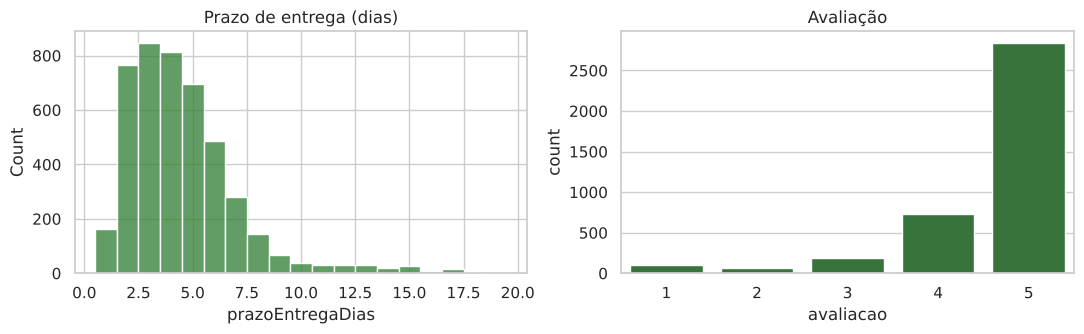

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(pedidos['prazoEntregaDias'].dropna().astype(int), discrete=True, ax=ax[0], color='#2e7d32')
ax[0].set_title('Prazo de entrega (dias)')
sns.countplot(x=pedidos['avaliacao'].dropna().astype(int), ax=ax[1], color='#2e7d32'); ax[1].set_title('Avaliação')
plt.tight_layout(); plt.show()

### 2.4 Verificação da qualidade (as mesmas regras do `techdf.sql`, V1–V6)

In [6]:
it = item.merge(produtos[['idProduto', 'precoLista']], on='idProduto')
chave = pedidos.merge(item.groupby('idPedido').apply(lambda g: tuple(sorted(zip(g.idProduto, g.quantidade)))).rename('itens'), left_on='idPedido', right_index=True)
qualidade = {
  'V1 campos obrigatórios nulos': int(pedidos[['idCliente', 'dataPedido', 'idFormaPagamento', 'status']].isna().any(axis=1).sum()),
  'V2 itens com quantidade <= 0': int((item['quantidade'] <= 0).sum()),
  'V3 pedidos com data futura': int((pedidos['dataPedido'] > FIM).sum()),
  'V4 preço > 10x o preço de lista': int((it['precoUnitario'] > 10 * it['precoLista']).sum()),
  'V5 pedidos duplicados': int(chave.duplicated(['idCliente', 'dataPedido', 'idFormaPagamento', 'itens']).sum()),
  'V6 cancelados com avaliação': int(((pedidos['status'] == 'Cancelado') & pedidos['avaliacao'].notna()).sum())}
qualidade

{'V1 campos obrigatórios nulos': 0,
 'V2 itens com quantidade <= 0': 25,
 'V3 pedidos com data futura': 30,
 'V4 preço > 10x o preço de lista': 142,
 'V5 pedidos duplicados': 45,
 'V6 cancelados com avaliação': 20}

## Fase 3 – Preparação dos dados
Selecionar → limpar → construir → integrar. As regras são as mesmas da view `pedido_limpo`/`item_limpo` do SQL.

In [7]:
# Selecionar: e-mail trocado por código pseudônimo (hash), como pede a LGPD
clientes['codCliente'] = clientes['emailCliente'].apply(lambda e: hashlib.sha256(e.encode()).hexdigest()[:10])
# Limpar
p = pedidos[pedidos['dataPedido'] <= FIM].copy()                                     # V3
p = p.merge(chave[['idPedido', 'itens']], on='idPedido')
p = p[~p.duplicated(['idCliente', 'dataPedido', 'idFormaPagamento', 'itens'])].drop(columns='itens')  # V5
p.loc[p['status'] == 'Cancelado', 'avaliacao'] = pd.NA                               # V6
i2 = it[it['idPedido'].isin(p['idPedido']) & (it['quantidade'] > 0)].copy()          # V2
erro = i2['precoUnitario'] > 10 * i2['precoLista']; i2.loc[erro, 'precoUnitario'] = (i2.loc[erro, 'precoUnitario'] / 100).round(2)  # V4
i2['valorItem'] = i2['quantidade'] * i2['precoUnitario']
i2 = i2.merge(produtos[['idProduto', 'idCategoria']], on='idProduto')
sub = i2.groupby('idPedido')['valorItem'].sum().rename('subtotal')
p = p.merge(sub, left_on='idPedido', right_index=True)
p['atrasado'] = p['prazoEntregaDias'] > 5
p = p.merge(clientes[['idCliente', 'codCliente', 'idRegiao', 'programaFidelidade']], on='idCliente').merge(regioes, on='idRegiao')
vendas = p[p['status'] == 'Entregue'].copy()     # receita = pedidos entregues
print('Pedidos limpos:', len(p), '| entregues:', len(vendas), '| itens limpos:', len(i2))

Pedidos limpos: 4691 | entregues: 4300 | itens limpos: 7806


### 3.1 Diagrama de dispersão com regressão linear: prazo × avaliação
Cada ponto é um cliente: prazo médio das suas entregas (x) e avaliação média que deu (y).

In [8]:
cli_av = vendas.dropna(subset=['avaliacao']).groupby('codCliente').agg(
    prazo=('prazoEntregaDias', 'mean'), aval=('avaliacao', 'mean'), regiao=('regiao', 'first'))
cli_av['aval'] = cli_av['aval'].astype(float); cli_av['prazo'] = cli_av['prazo'].astype(float)
distantes = ['Sobradinho', 'Samambaia', 'Ceilândia', 'Gama']
cli_av['grupo'] = np.where(cli_av['regiao'].isin(distantes), 'Regiões distantes', 'Regiões próximas')
def reta(d):
    m = LinearRegression().fit(d[['prazo']], d['aval'])
    return dict(clientes=len(d), inclinacao=m.coef_[0], intercepto=m.intercept_, r2=m.score(d[['prazo']], d['aval']),
                prazo_medio=d['prazo'].mean(), aval_media=d['aval'].mean())
reg = pd.DataFrame({'Todos': reta(cli_av), **{g: reta(d) for g, d in cli_av.groupby('grupo')}}).T
reg.to_csv(f'{PROC}/regressao_dispersao.csv'); reg.round(3)

,clientes,inclinacao,intercepto,r2,prazo_medio,aval_media
Todos,1141.0,-0.270,5.810,0.722,4.875,4.494
Regiões distantes,496.0,-0.344,6.383,0.731,6.339,4.202
Regiões próximas,645.0,-0.264,5.707,0.707,3.749,4.718


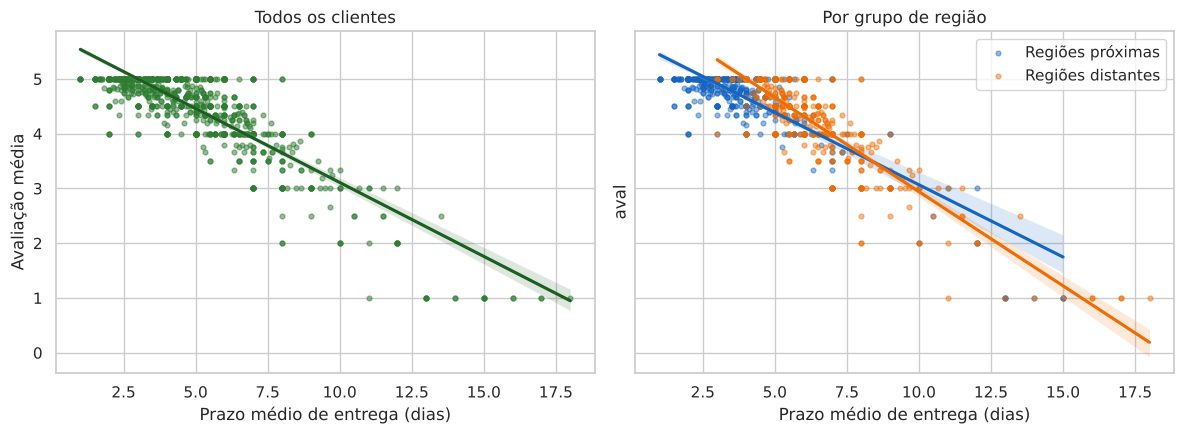

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
sns.regplot(data=cli_av, x='prazo', y='aval', ax=ax[0], scatter_kws=dict(s=12, alpha=.5, color='#2e7d32'), line_kws=dict(color='#1b5e20'))
ax[0].set_title('Todos os clientes'); ax[0].set_xlabel('Prazo médio de entrega (dias)'); ax[0].set_ylabel('Avaliação média')
for g, cor in [('Regiões próximas', '#1565c0'), ('Regiões distantes', '#ef6c00')]:
    sns.regplot(data=cli_av[cli_av.grupo == g], x='prazo', y='aval', ax=ax[1], label=g, scatter_kws=dict(s=12, alpha=.45, color=cor), line_kws=dict(color=cor))
ax[1].legend(); ax[1].set_title('Por grupo de região'); ax[1].set_xlabel('Prazo médio de entrega (dias)')
plt.tight_layout(); plt.show()

### 3.2 Tabelas analíticas
* **Tabela de clientes (P1):** recência, frequência, valor, ticket médio e % do gasto em Games + Notebooks, calculados na data da extração.
* **Tabela de risco (P2):** uma linha por cliente em uma **data de corte**; atributos usam só o que aconteceu até o corte, e o alvo é "nenhum pedido nos 90 dias seguintes".

In [10]:
def atributos(corte, janela=180):
    h = p[(p['dataPedido'] <= corte)]
    hv = h[h['status'] == 'Entregue']
    ativos = hv[hv['dataPedido'] > corte - pd.Timedelta(days=janela)]['codCliente'].unique()
    hv = hv[hv['codCliente'].isin(ativos) & (hv['dataPedido'] > corte - pd.Timedelta(days=365))]   # histórico dos últimos 12 meses
    g = hv.groupby('codCliente')
    hi = i2.merge(hv[['idPedido', 'codCliente']], on='idPedido')
    alto = hi[hi['idCategoria'].isin([1, 7])].groupby('codCliente')['valorItem'].sum()
    d = pd.DataFrame({'recencia_dias': (corte - g['dataPedido'].max()).dt.days,
                      'frequencia': g.size(),
                      'valor_total': g['subtotal'].sum(),
                      'prazo_medio': g['prazoEntregaDias'].mean().astype(float),
                      'perc_atrasados': g['atrasado'].mean().astype(float),
                      'aval_media': g['avaliacao'].mean().astype(float),
                      'ultimo_atrasado': g.apply(lambda x: x.sort_values('dataPedido')['atrasado'].iloc[-1]).astype(int),
                      'perc_boleto': g['idFormaPagamento'].apply(lambda s: (s == 3).mean()),
                      'cancelamentos': h[h['codCliente'].isin(ativos)].groupby('codCliente')['status'].apply(lambda s: (s == 'Cancelado').sum())})
    d['ticket_medio'] = d['valor_total'] / d['frequencia']
    d['perc_games_notebooks'] = (alto.reindex(d.index).fillna(0) / d['valor_total']).clip(0, 1)
    cad = clientes.set_index('codCliente')
    d['dias_cadastro'] = (corte - cad.loc[d.index, 'dataCadastro']).dt.days.values
    d['fidelidade'] = cad.loc[d.index, 'programaFidelidade'].astype(int).values
    d['regiao_distante'] = cad.loc[d.index, 'idRegiao'].isin([5, 6, 7, 8]).astype(int).values
    d['aval_media'] = d['aval_media'].fillna(d['aval_media'].median())
    futuro = p[(p['dataPedido'] > corte) & (p['dataPedido'] <= corte + pd.Timedelta(days=90))]['codCliente'].unique()
    d['abandono_90d'] = (~d.index.isin(futuro)).astype(int)
    d['corte'] = corte.date()
    return d
cortes = [pd.Timestamp(x) for x in ['2025-09-30', '2025-12-31', '2026-03-31']]
risco = pd.concat([atributos(c) for c in cortes])
clientes_p1 = atributos(FIM).drop(columns=['abandono_90d', 'corte'])
risco.to_csv(f'{PROC}/tabela_risco.csv'); clientes_p1.to_csv(f'{PROC}/tabela_clientes.csv')
print('Tabela de risco:', risco.shape, '| clientes P1:', clientes_p1.shape)
print(risco.groupby('corte')['abandono_90d'].agg(['size', 'mean']).round(3))

Tabela de risco: (2171, 16) | clientes P1: (737, 14)
            size   mean
corte                  
2025-09-30   599  0.531
2025-12-31   727  0.524
2026-03-31   845  0.538


## Fase 4 – Modelagem
### P1 – K-means (k de 3 a 6)

In [11]:
cols_p1 = ['recencia_dias', 'frequencia', 'valor_total', 'ticket_medio', 'perc_games_notebooks']
X1 = clientes_p1[cols_p1].copy()
for c in ['recencia_dias', 'frequencia', 'valor_total', 'ticket_medio']: X1[c] = np.log1p(X1[c])
Z1 = StandardScaler().fit_transform(X1)
sil = {}
for k in range(3, 7):
    km = KMeans(k, n_init=20, random_state=SEMENTE).fit(Z1); sil[k] = silhouette_score(Z1, km.labels_)
print({k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get)
km = KMeans(K, n_init=20, random_state=SEMENTE).fit(Z1)
clientes_p1['cluster'] = km.labels_
perfil = clientes_p1.groupby('cluster')[cols_p1].median().round(2)
perfil['clientes'] = clientes_p1['cluster'].value_counts().sort_index()
perfil['perc_clientes'] = (perfil['clientes'] / len(clientes_p1)).round(3)
perfil

{3: 0.31, 4: 0.283, 5: 0.266, 6: 0.26}


,recencia_dias,frequencia,valor_total,ticket_medio,perc_games_notebooks,clientes,perc_clientes
cluster,,,,,,,
0,16.5,6.0,17964.93,2839.51,0.27,214,0.290
1,96.0,2.0,1554.38,593.03,0.00,259,0.351
2,98.0,3.0,10652.12,4350.56,0.75,264,0.358


### P2 – Classificadores com teste temporal
Treino: cortes de set./2025 e dez./2025 (alvos observados até mar./2026). Teste: corte de mar./2026 (alvo de abr. a jun./2026).

In [12]:
cols_p2 = ['recencia_dias', 'frequencia', 'valor_total', 'ticket_medio', 'prazo_medio', 'perc_atrasados', 'aval_media',
           'ultimo_atrasado', 'perc_boleto', 'cancelamentos', 'dias_cadastro', 'fidelidade', 'regiao_distante']
tr = risco[risco['corte'] < cortes[-1].date()]; te = risco[risco['corte'] == cortes[-1].date()]
Xtr, ytr, Xte, yte = tr[cols_p2], tr['abandono_90d'], te[cols_p2], te['abandono_90d']
print('Treino:', len(tr), 'taxa de abandono', round(ytr.mean(), 3), '| Teste:', len(te), 'taxa', round(yte.mean(), 3))
modelos = {'Regressão logística (base)': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
           'Árvore de decisão': DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, class_weight='balanced', random_state=SEMENTE),
           'Random Forest': RandomForestClassifier(400, max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=SEMENTE)}
met, prob = [], {}
for nome, m in modelos.items():
    m.fit(Xtr, ytr); pr = m.predict_proba(Xte)[:, 1]; prev = (pr >= 0.5).astype(int); prob[nome] = pr
    met.append({'modelo': nome, 'recall': recall_score(yte, prev), 'precisao': precision_score(yte, prev),
                'f1': f1_score(yte, prev), 'auc': roc_auc_score(yte, pr)})
metricas = pd.DataFrame(met).set_index('modelo').round(3); metricas.to_csv(f'{PROC}/metricas_modelos.csv'); metricas

Treino: 1326 taxa de abandono 0.527 | Teste: 845 taxa 0.538


,recall,precisao,f1,auc
modelo,,,,
Regressão logística (base),0.640,0.683,0.661,0.690
Árvore de decisão,0.473,0.724,0.572,0.682
Random Forest,0.620,0.668,0.643,0.694


In [13]:
rf = modelos['Random Forest']
imp = pd.Series(rf.feature_importances_, index=cols_p2).sort_values(ascending=False).round(3); imp.head(6)

recencia_dias      0.286
ultimo_atrasado    0.124
dias_cadastro      0.107
prazo_medio        0.089
valor_total        0.088
ticket_medio       0.081
dtype: float64

## Fase 5 – Avaliação
Com o corte padrão de 0,5, nenhum modelo atinge recall ≥ 0,70, e o melhor F1 é o da própria regressão logística (modelo base).
**Iteração (volta à Fase 4):** escolher o limiar de decisão **sem tocar no teste**, com uma validação temporal dentro do treino: treina no corte de set./2025 e valida no de dez./2025.

In [14]:
melhor = metricas['f1'].idxmax()
print('Melhor F1 no teste com limiar 0,5:', melhor)
c1, c2 = cortes[0].date(), cortes[1].date()
val_m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))
val_m.fit(risco.loc[risco.corte == c1, cols_p2], risco.loc[risco.corte == c1, 'abandono_90d'])
pv = val_m.predict_proba(risco.loc[risco.corte == c2, cols_p2])[:, 1]; yv = risco.loc[risco.corte == c2, 'abandono_90d']
grade = pd.DataFrame([{'limiar': l, 'recall': recall_score(yv, pv >= l), 'precisao': precision_score(yv, pv >= l), 'f1': f1_score(yv, pv >= l)}
                      for l in np.arange(0.30, 0.61, 0.025)]).round(3)
LIMIAR = float(grade[grade['recall'] >= 0.70]['limiar'].max())
print('Limiar escolhido na validação (maior limiar com recall >= 0,70):', round(LIMIAR, 3))
grade

Melhor F1 no teste com limiar 0,5: Regressão logística (base)
Limiar escolhido na validação (maior limiar com recall >= 0,70): 0.45


,limiar,recall,precisao,f1
0,0.300,0.927,0.575,0.710
1,0.325,0.890,0.584,0.706
2,0.350,0.858,0.596,0.703
3,0.375,0.822,0.603,0.696
4,0.400,0.798,0.612,0.692
5,0.425,0.766,0.613,0.681
6,0.450,0.719,0.623,0.667
7,0.475,0.680,0.621,0.649
8,0.500,0.643,0.619,0.631
9,0.525,0.617,0.642,0.629


In [15]:
final = modelos['Regressão logística (base)']           # já treinado nos cortes de treino
prev = (prob['Regressão logística (base)'] >= LIMIAR).astype(int)
teste_final = pd.Series({'recall': recall_score(yte, prev), 'precisao': precision_score(yte, prev), 'f1': f1_score(yte, prev),
                         'auc': roc_auc_score(yte, prob['Regressão logística (base)']), 'alertas_%': prev.mean()}).round(3)
print('Teste final – regressão logística com limiar', round(LIMIAR, 3)); print(teste_final)
coef = pd.Series(final[-1].coef_[0], index=cols_p2).sort_values(); print('\nCoeficientes padronizados:'); print(coef.round(3))
te2 = te.assign(prev=prev)
por_grupo = []
for nome, mask in [('Último pedido atrasado', te2['ultimo_atrasado'] == 1), ('Último pedido no prazo', te2['ultimo_atrasado'] == 0),
                   ('Regiões distantes', te2['regiao_distante'] == 1), ('Regiões próximas', te2['regiao_distante'] == 0),
                   ('1 pedido no histórico', te2['frequencia'] == 1), ('2 ou mais pedidos', te2['frequencia'] >= 2)]:
    d = te2[mask]
    por_grupo.append({'grupo': nome, 'clientes': len(d), 'taxa_abandono': d['abandono_90d'].mean(),
                      'recall': recall_score(d['abandono_90d'], d['prev']), 'precisao': precision_score(d['abandono_90d'], d['prev'], zero_division=0)})
por_grupo = pd.DataFrame(por_grupo).set_index('grupo').round(3); por_grupo.to_csv(f'{PROC}/desempenho_por_grupo.csv')
pd.concat([metricas, pd.DataFrame([teste_final.drop('alertas_%')], index=['Reg. logística, limiar ' + f'{LIMIAR:.2f}'.replace('.', ',')])]).to_csv(f'{PROC}/metricas_modelos.csv')
por_grupo

Teste final – regressão logística com limiar 0.45
recall       0.723
precisao     0.651
f1           0.685
auc          0.690
alertas_%    0.598
dtype: float64

Coeficientes padronizados:
frequencia        -0.452
perc_atrasados    -0.450
cancelamentos     -0.122
ticket_medio      -0.073
regiao_distante   -0.019
aval_media        -0.017
fidelidade         0.012
perc_boleto        0.095
prazo_medio        0.158
valor_total        0.164
dias_cadastro      0.279
recencia_dias      0.347
ultimo_atrasado    0.737
dtype: float64


,clientes,taxa_abandono,recall,precisao
grupo,,,,
Último pedido atrasado,272,0.724,0.975,0.741
Último pedido no prazo,573,0.450,0.531,0.557
Regiões distantes,349,0.636,0.824,0.712
Regiões próximas,496,0.470,0.627,0.589
1 pedido no histórico,248,0.573,0.718,0.646
2 ou mais pedidos,597,0.524,0.725,0.654


In [16]:
# Hipóteses H1–H3 na base limpa
h1 = risco.groupby('ultimo_atrasado')['abandono_90d'].mean().round(3)
h2 = vendas.groupby('regiao').agg(prazo_medio=('prazoEntregaDias', 'mean'), perc_atraso=('atrasado', 'mean')).astype(float).round(3).sort_values('prazo_medio')
h3 = clientes_p1.groupby('fidelidade')['frequencia'].mean().round(2)
print('H1 – abandono por último pedido atrasado (0 = no prazo, 1 = atrasado):', h1.to_dict())
print('H3 – frequência média por fidelidade (0/1):', h3.to_dict()); h2

H1 – abandono por último pedido atrasado (0 = no prazo, 1 = atrasado): {0: 0.445, 1: 0.709}
H3 – frequência média por fidelidade (0/1): {0: 3.41, 1: 5.53}


,prazo_medio,perc_atraso
regiao,,
Plano Piloto,3.120,0.077
Guará,3.131,0.082
Águas Claras,3.694,0.100
Taguatinga,4.131,0.137
Sobradinho,5.328,0.294
Samambaia,5.777,0.402
Ceilândia,6.327,0.558
Gama,7.260,0.864


In [17]:
# Iteração: k = 4 (segunda melhor silhueta?) para ver se separa algum grupo útil
k2 = sorted(sil, key=sil.get, reverse=True)[1]
km2 = KMeans(k2, n_init=20, random_state=SEMENTE).fit(Z1)
tmp = clientes_p1.assign(c2=km2.labels_).groupby('c2')[cols_p1].median().round(2); tmp['clientes'] = pd.Series(km2.labels_).value_counts().sort_index()
print('k alternativo =', k2, '| silhueta', round(sil[k2], 3)); tmp

k alternativo = 4 | silhueta 0.283


,recencia_dias,frequencia,valor_total,ticket_medio,perc_games_notebooks,clientes
c2,,,,,,
0,107.0,2.0,675.30,364.59,0.00,142
1,14.0,7.0,20811.27,3025.20,0.37,175
2,97.0,3.0,11088.46,4350.56,0.82,220
3,75.0,3.0,4524.92,1626.82,0.00,200


## Fase 6 – Implementação: protótipo do job mensal

In [18]:
# Nome e ação de cada segmento, a partir das medianas da Fase 4
med = clientes_p1.groupby('cluster')[cols_p1].median()
fiel = med['frequencia'].idxmax(); alto = med.drop(fiel)['perc_games_notebooks'].idxmax()
baixo = [c for c in med.index if c not in (fiel, alto)][0]
NOMES = {fiel: 'Fiéis de alto valor', alto: 'Alto ticket em games e notebooks', baixo: 'Ocasionais de baixo ticket'}
ACAO = {'Fiéis de alto valor': 'Convite ao programa de fidelidade e acesso antecipado a lançamentos (sem cupom de desconto)',
        'Alto ticket em games e notebooks': 'Oferta de acessórios complementares e garantia estendida após a compra',
        'Ocasionais de baixo ticket': 'Frete grátis acima de R$ 299 e desconto no Pix para aumentar o ticket'}
perfil.index = perfil.index.map(NOMES); perfil.to_csv(f'{PROC}/perfis_kmeans.csv'); perfil

,recencia_dias,frequencia,valor_total,ticket_medio,perc_games_notebooks,clientes,perc_clientes
cluster,,,,,,,
Fiéis de alto valor,16.5,6.0,17964.93,2839.51,0.27,214,0.290
Ocasionais de baixo ticket,96.0,2.0,1554.38,593.03,0.00,259,0.351
Alto ticket em games e notebooks,98.0,3.0,10652.12,4350.56,0.75,264,0.358


In [19]:
corte_job = FIM
atual = atributos(corte_job)
final.fit(risco[cols_p2], risco['abandono_90d'])          # retreino com todos os cortes rotulados
atual['prob_abandono'] = final.predict_proba(atual[cols_p2])[:, 1]
atual['segmento'] = clientes_p1.loc[atual.index, 'cluster'].map(NOMES)
atual['acao'] = atual['segmento'].map(ACAO)
atual['alerta'] = atual['prob_abandono'] >= LIMIAR
saida = atual[['segmento', 'acao', 'prob_abandono', 'alerta']].round(3)
saida.to_csv(f'{PROC}/saida_job_mensal.csv')
print('Clientes ativos no job de jul./2026:', len(saida), '| alertas:', int(saida['alerta'].sum()))
print(saida.groupby('segmento')['alerta'].agg(['size', 'sum']))
saida.head()

Clientes ativos no job de jul./2026: 737 | alertas: 508
                                  size  sum
segmento                                   
Alto ticket em games e notebooks   264  225
Fiéis de alto valor                214   65
Ocasionais de baixo ticket         259  218


,segmento,acao,prob_abandono,alerta
codCliente,,,,
009b392957,Ocasionais de baixo ticket,Frete grátis acima de R$ 299 e desconto no Pix...,0.684,True
00d08785b8,Alto ticket em games e notebooks,Oferta de acessórios complementares e garantia...,0.796,True
0178c820c4,Fiéis de alto valor,Convite ao programa de fidelidade e acesso ant...,0.244,False
019632d46b,Alto ticket em games e notebooks,Oferta de acessórios complementares e garantia...,0.416,False
01fc49d51d,Fiéis de alto valor,Convite ao programa de fidelidade e acesso ant...,0.409,False


In [20]:
# Monitoramento simples de drift: média dos atributos no treino × no corte mais recente
cols_drift = [c for c in cols_p2 if c != 'dias_cadastro']
drift = pd.DataFrame({'treino': tr[cols_drift].mean(), 'recente': atual[cols_drift].mean()})
drift['variacao_%'] = ((drift['recente'] / drift['treino'] - 1) * 100).round(1)
drift.round(2)

,treino,recente,variacao_%
recencia_dias,61.11,75.31,23.2
frequencia,2.74,3.91,42.7
valor_total,8268.06,11592.74,40.2
ticket_medio,3157.93,3110.94,-1.5
prazo_medio,4.74,4.59,-3.2
perc_atrasados,0.29,0.28,-2.4
aval_media,4.55,4.57,0.4
ultimo_atrasado,0.33,0.35,3.8
perc_boleto,0.12,0.12,-0.1
cancelamentos,0.17,0.30,77.5


O aumento de frequência e valor não é mudança de comportamento: a loja começou em jan./2025, então os cortes de treino têm menos meses de histórico. O monitoramento real deveria comparar janelas de mesmo tamanho.
## Dashboard (Pandas + Seaborn + Matplotlib, no lugar do Power BI)

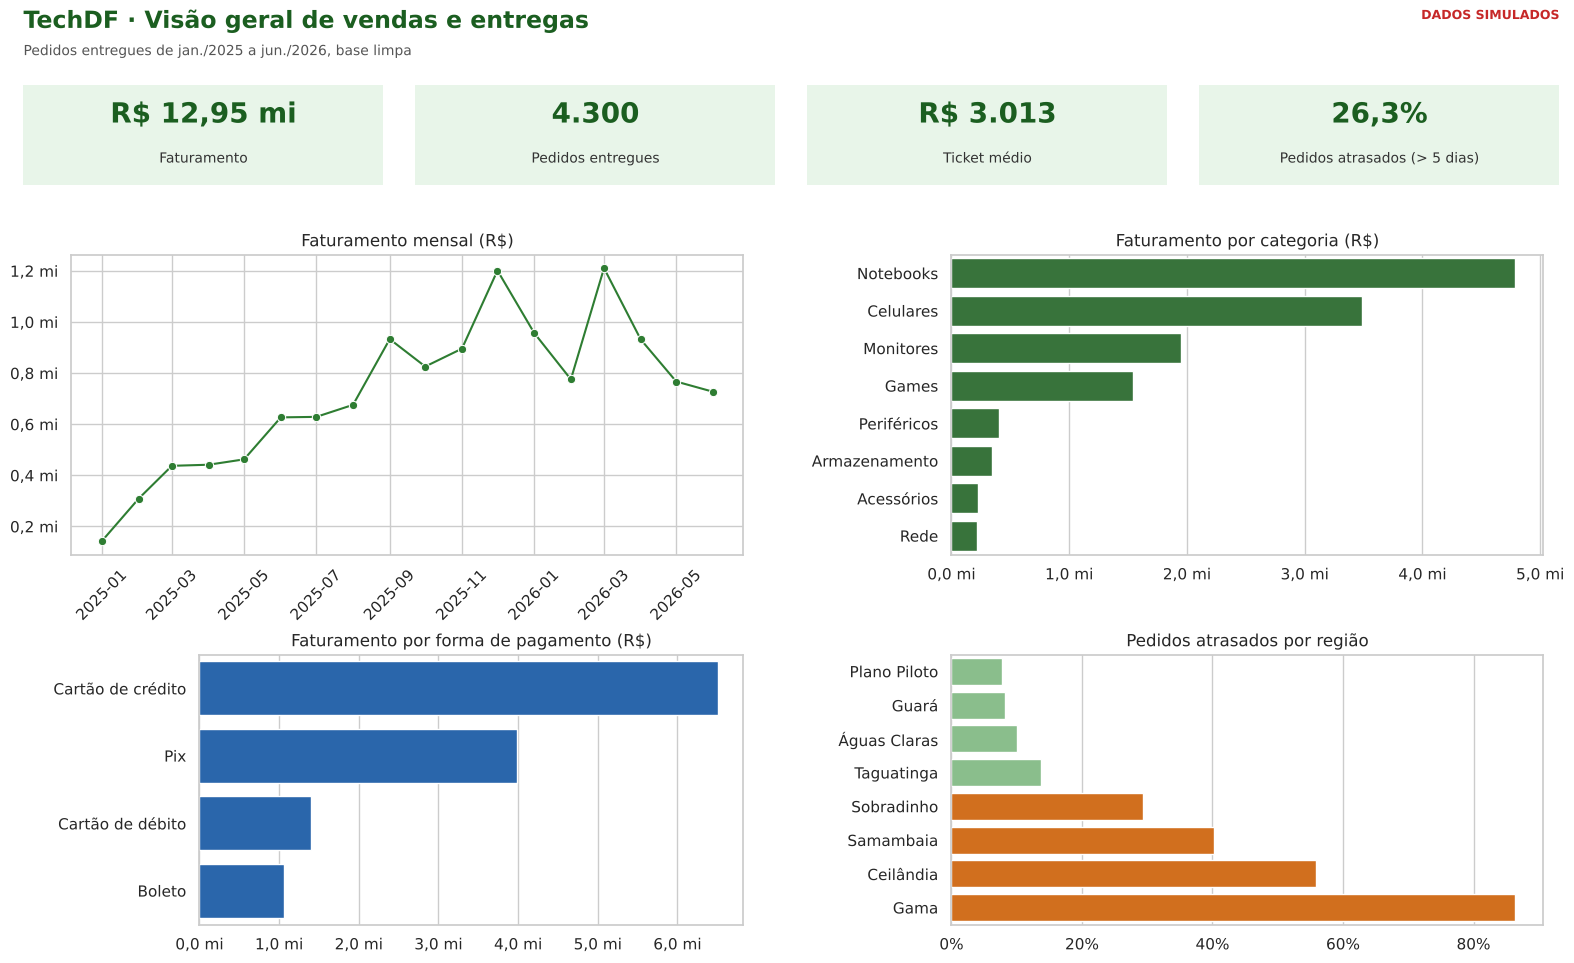

In [21]:
VERDE, AZUL, LARANJA, CINZA = '#2e7d32', '#1565c0', '#ef6c00', '#9e9e9e'
MI = plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f} mi'.replace('.', ','))
def cabecalho(fig, titulo, sub):
    fig.text(0.02, 0.975, titulo, fontsize=17, weight='bold', color='#1b5e20', va='top')
    fig.text(0.02, 0.94, sub, fontsize=10, color='#555', va='top')
    fig.text(0.98, 0.975, 'DADOS SIMULADOS', fontsize=9, weight='bold', color='#c62828', ha='right', va='top')
# ---------- Página 1 ----------
mens = vendas.assign(mes=vendas['dataPedido'].dt.to_period('M').dt.to_timestamp()).groupby('mes').agg(faturamento=('subtotal', 'sum'), pedidos=('idPedido', 'count')).reset_index()
cat = i2[i2['idPedido'].isin(vendas['idPedido'])].merge(categorias, on='idCategoria').groupby('categoria')['valorItem'].sum().sort_values(ascending=False).reset_index()
pag = vendas.merge(formas, on='idFormaPagamento').groupby('formaPagamento')['subtotal'].sum().sort_values(ascending=False).reset_index()
reg_kpi = vendas.groupby('regiao').agg(perc_atraso=('atrasado', 'mean')).astype(float).sort_values('perc_atraso').reset_index()
fig = plt.figure(figsize=(16, 10)); cabecalho(fig, 'TechDF · Visão geral de vendas e entregas', 'Pedidos entregues de jan./2025 a jun./2026, base limpa')
kp = [('Faturamento', f"R$ {vendas['subtotal'].sum()/1e6:.2f} mi".replace('.', ',')), ('Pedidos entregues', f"{len(vendas):,}".replace(',', '.')),
      ('Ticket médio', f"R$ {vendas['subtotal'].mean():,.0f}".replace(',', '.')), ('Pedidos atrasados (> 5 dias)', f"{vendas['atrasado'].mean():.1%}".replace('.', ','))]
for j, (t, v) in enumerate(kp):
    a = fig.add_axes([0.02 + j * 0.245, 0.80, 0.225, 0.1]); a.axis('off'); a.add_patch(plt.Rectangle((0, 0), 1, 1, color='#e8f5e9', transform=a.transAxes))
    a.text(0.5, 0.62, v, ha='center', fontsize=20, weight='bold', color='#1b5e20'); a.text(0.5, 0.22, t, ha='center', fontsize=10, color='#333')
a1 = fig.add_axes([0.05, 0.43, 0.42, 0.3]); sns.lineplot(data=mens, x='mes', y='faturamento', marker='o', color=VERDE, ax=a1)
a1.set_title('Faturamento mensal (R$)'); a1.yaxis.set_major_formatter(MI); a1.set_xlabel(''); a1.set_ylabel(''); a1.tick_params(axis='x', rotation=45)
a2 = fig.add_axes([0.60, 0.43, 0.37, 0.3]); sns.barplot(data=cat, y='categoria', x='valorItem', color=VERDE, ax=a2); a2.set_title('Faturamento por categoria (R$)'); a2.xaxis.set_major_formatter(MI); a2.set_xlabel(''); a2.set_ylabel('')
a3 = fig.add_axes([0.13, 0.06, 0.34, 0.27]); sns.barplot(data=pag, y='formaPagamento', x='subtotal', color=AZUL, ax=a3); a3.set_title('Faturamento por forma de pagamento (R$)'); a3.xaxis.set_major_formatter(MI); a3.set_xlabel(''); a3.set_ylabel('')
a4 = fig.add_axes([0.60, 0.06, 0.37, 0.27]); sns.barplot(data=reg_kpi, y='regiao', x='perc_atraso', palette=['#81c784'] * 4 + ['#ef6c00'] * 4, ax=a4)
a4.set_title('Pedidos atrasados por região'); a4.set_xlabel(''); a4.set_ylabel(''); a4.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
fig.savefig(f'{DASH}/01_visao_geral.png', dpi=110); plt.show()

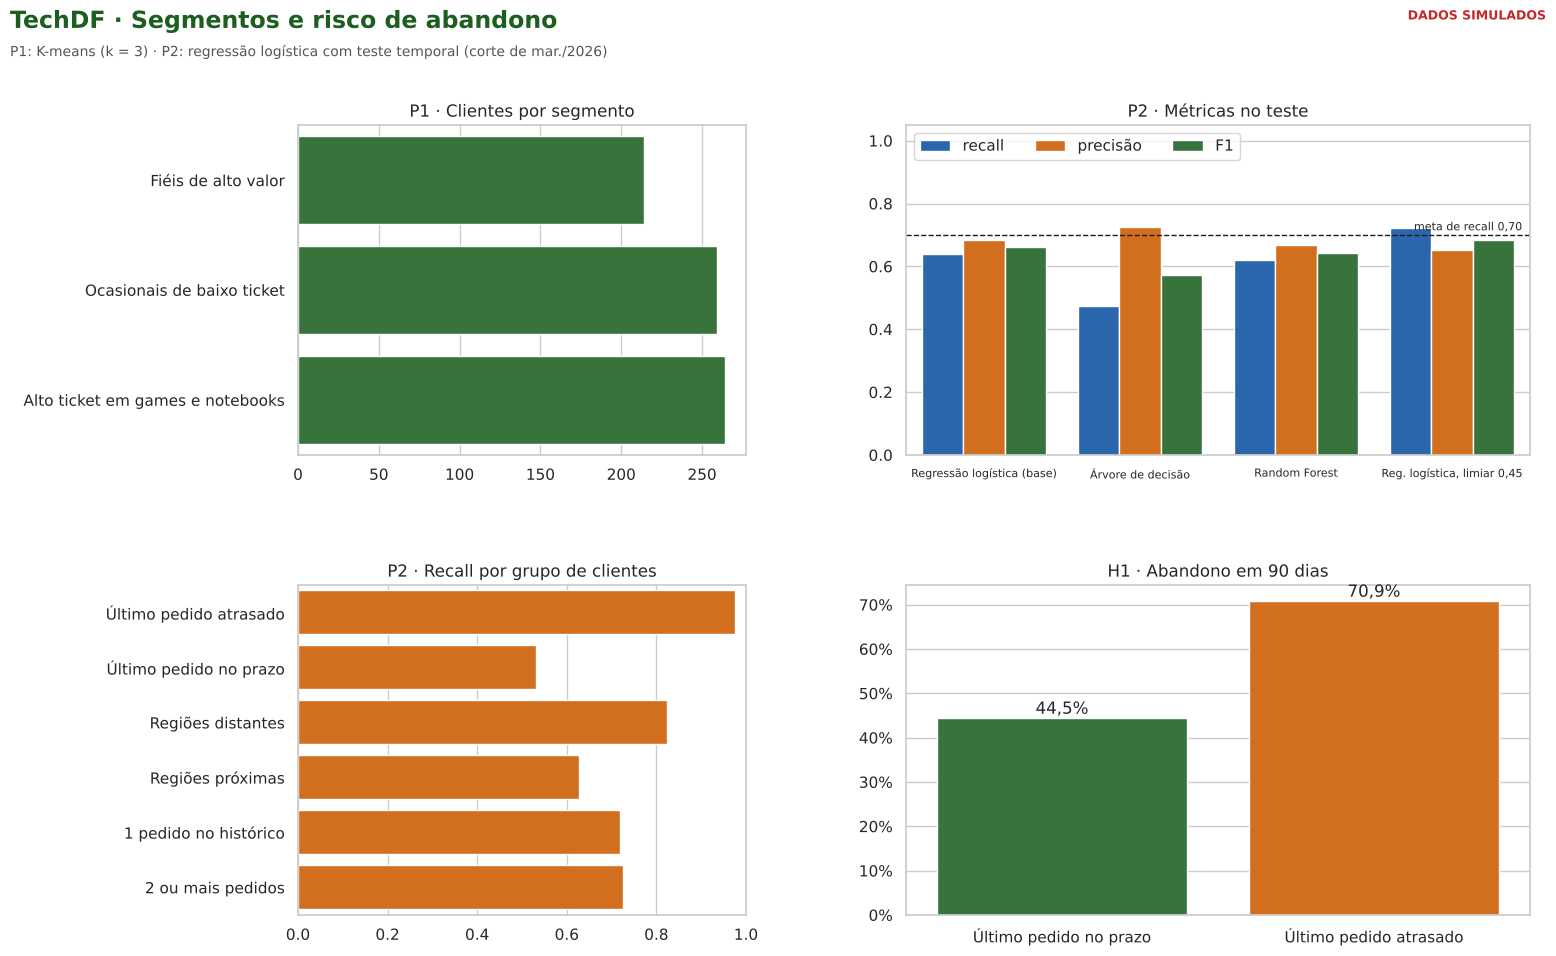

In [22]:
# ---------- Página 2 ----------
fig = plt.figure(figsize=(16, 10)); cabecalho(fig, 'TechDF · Segmentos e risco de abandono', f'P1: K-means (k = {K}) · P2: regressão logística com teste temporal (corte de mar./2026)')
b1 = fig.add_axes([0.2, 0.53, 0.28, 0.33]); seg = perfil.reset_index().rename(columns={'cluster': 'segmento'})
sns.barplot(data=seg, y='segmento', x='clientes', color=VERDE, ax=b1); b1.set_title('P1 · Clientes por segmento'); b1.set_xlabel(''); b1.set_ylabel('')
mt = pd.read_csv(f'{PROC}/metricas_modelos.csv', index_col=0)[['recall', 'precisao', 'f1']].reset_index().melt(id_vars='index')
b2 = fig.add_axes([0.58, 0.53, 0.39, 0.33]); sns.barplot(data=mt, x='index', y='value', hue='variable', palette=[AZUL, LARANJA, VERDE], ax=b2)
b2.axhline(0.70, ls='--', color='k', lw=1); b2.text(3.45, 0.715, 'meta de recall 0,70', fontsize=8, ha='right'); b2.set_ylim(0, 1.05)
b2.set_title('P2 · Métricas no teste'); b2.set_xlabel(''); b2.set_ylabel(''); b2.tick_params(axis='x', labelsize=8)
h_, l_ = b2.get_legend_handles_labels(); b2.legend(h_, ['recall', 'precisão', 'F1'], title='', loc='upper left', ncol=3)
b3 = fig.add_axes([0.2, 0.07, 0.28, 0.33]); pg = por_grupo.reset_index()
sns.barplot(data=pg, y='grupo', x='recall', color=LARANJA, ax=b3); b3.set_title('P2 · Recall por grupo de clientes'); b3.set_xlabel(''); b3.set_ylabel(''); b3.set_xlim(0, 1)
b4 = fig.add_axes([0.58, 0.07, 0.39, 0.33]); hh = h1.rename(index={0: 'Último pedido no prazo', 1: 'Último pedido atrasado'}).reset_index()
sns.barplot(data=hh, x='ultimo_atrasado', y='abandono_90d', palette=[VERDE, LARANJA], ax=b4); b4.set_title('H1 · Abandono em 90 dias'); b4.set_xlabel(''); b4.set_ylabel('')
b4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
for c in b4.containers: b4.bar_label(c, labels=[f'{v:.1%}'.replace('.', ',') for v in c.datavalues])
fig.savefig(f'{DASH}/02_modelos.png', dpi=110); plt.show()

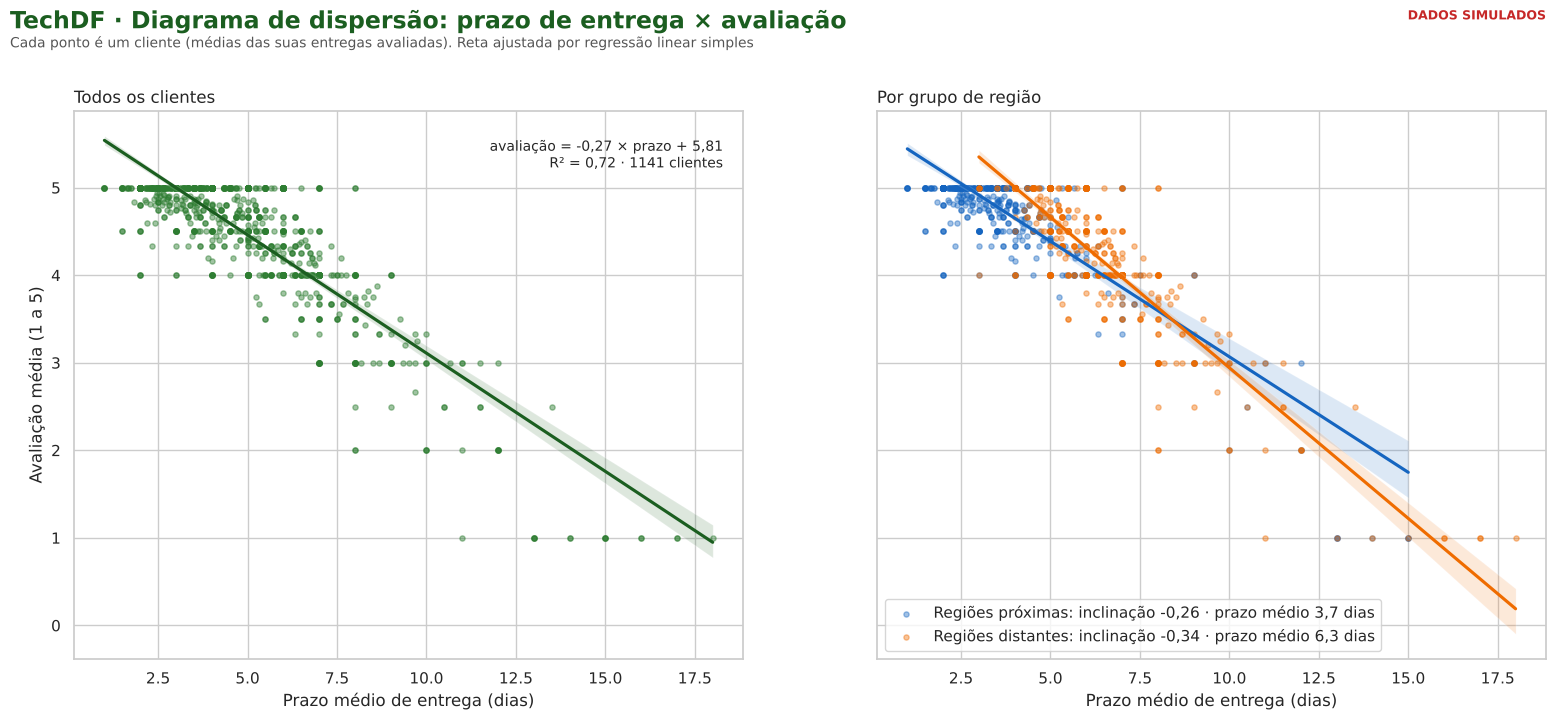

In [23]:
# ---------- Página 3 ----------
fig, ax = plt.subplots(1, 2, figsize=(16, 7.5), sharey=True); fig.subplots_adjust(top=0.84, left=0.06, right=0.98)
cabecalho(fig, 'TechDF · Diagrama de dispersão: prazo de entrega × avaliação', 'Cada ponto é um cliente (médias das suas entregas avaliadas). Reta ajustada por regressão linear simples')
t = reg.loc['Todos']
sns.regplot(data=cli_av, x='prazo', y='aval', ax=ax[0], scatter_kws=dict(s=14, alpha=.45, color=VERDE), line_kws=dict(color='#1b5e20'))
ax[0].set_title('Todos os clientes', loc='left'); ax[0].set_xlabel('Prazo médio de entrega (dias)'); ax[0].set_ylabel('Avaliação média (1 a 5)')
ax[0].text(0.97, 0.95, f"avaliação = {t.inclinacao:.2f} × prazo + {t.intercepto:.2f}\nR² = {t.r2:.2f} · {int(t.clientes)} clientes".replace('.', ','), transform=ax[0].transAxes, ha='right', va='top', fontsize=10)
for g, cor in [('Regiões próximas', AZUL), ('Regiões distantes', LARANJA)]:
    r_ = reg.loc[g]
    sns.regplot(data=cli_av[cli_av.grupo == g], x='prazo', y='aval', ax=ax[1], scatter_kws=dict(s=14, alpha=.4, color=cor), line_kws=dict(color=cor),
                label=f"{g}: inclinação {r_.inclinacao:.2f} · prazo médio {r_.prazo_medio:.1f} dias".replace('.', ','))
ax[1].legend(loc='lower left'); ax[1].set_title('Por grupo de região', loc='left'); ax[1].set_xlabel('Prazo médio de entrega (dias)'); ax[1].set_ylabel('')
fig.savefig(f'{DASH}/03_dispersao_prazo_avaliacao.png', dpi=110); plt.show()